# EDA: channels, videos, training subset, new channels

In [1]:
"""Reproduces the EDA slides (All Channels, All Videos, Training Subset: Channels, Training Subset: Videos).
Everything comes from the BigQuery tables youtube.channels and youtube.videos; genres come from the YouTube API."""
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from googleapiclient.discovery import build

sys.path.insert(0, os.path.abspath("../src"))
import config

RED, ACCENT, GRAY, INK = "#990000", "#C44545", "#C9C9C9", "#1A1A1A"
plt.rcParams.update({"font.family": ["Arial", "Helvetica"], "axes.spines.top": False, "axes.spines.right": False})

## Load channels and videos

In [2]:
client = bigquery.Client(project=config.GCP_PROJECT_ID, location=config.BQ_LOCATION)
dataset = f"{config.GCP_PROJECT_ID}.{config.BQ_DATASET}"

# subscriberCount is stored as a string in youtube.channels, so cast it.
df_channels = client.query(f"""
    SELECT id AS channel_id, snippet_title AS channel_title, CAST(statistics_subscriberCount AS INT64) AS subs
    FROM `{dataset}.channels`
""").to_dataframe()

df_videos = client.query(f"""
    SELECT id, snippet_channelId AS channel_id, snippet_channelTitle AS channel_title, snippet_categoryId AS category_id,
        COALESCE(duration_seconds, 0) AS duration_seconds, snippet_publishedAt AS published_at,
        statistics_viewCount AS views, CAST(statistics_likeCount AS INT64) AS likes, COALESCE(age_days_at_pull, 0) AS age_days
    FROM `{dataset}.videos`
""").to_dataframe()
# A channel's first daily snapshot marks when it joined the sheet (2026-10-15 = the original list).
df_first_seen = client.query(f"""
    SELECT channel_id, MIN(snapshot_date) AS first_seen FROM `{dataset}.channel_daily_snapshots` GROUP BY channel_id
""").to_dataframe()
df_channels = df_channels.merge(df_first_seen, on="channel_id", how="left")
df_channels["is_new"] = df_channels["first_seen"] > df_channels["first_seen"].min()
print(f"{len(df_channels)} channels ({df_channels['is_new'].sum()} new), {len(df_videos):,} videos")

/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


52 channels (6 new), 13,188 videos


## Genre from the YouTube API

In [3]:
"""Every video carries snippet.categoryId (set by the uploader). videoCategories.list maps the ids to names, and a
channel's genre is the category most common among its videos."""
youtube = build("youtube", "v3", developerKey=config.YOUTUBE_API_KEY)
category_titles = {item["id"]: item["snippet"]["title"] for item in youtube.videoCategories().list(part="snippet", regionCode="US").execute()["items"]}
df_videos["genre"] = df_videos["category_id"].map(category_titles)

df_channel_genre = df_videos.groupby("channel_id")["genre"].agg(lambda genres: genres.value_counts().idxmax()).rename("genre").reset_index()
df_channels = df_channels.merge(df_channel_genre, on="channel_id")
df_channels["genre"].value_counts()

genre
Entertainment           13
Education                9
People & Blogs           8
Science & Technology     5
Sports                   3
News & Politics          3
Howto & Style            3
Gaming                   2
Comedy                   2
Autos & Vehicles         1
Pets & Animals           1
Travel & Events          1
Name: count, dtype: int64

## Training subset

In [4]:
"""The modeling sample: videos the LLM tagged before config.ANALYSIS_TAGGED_BEFORE (tagging continues after it,
but the analysis is frozen on this set)."""
df_tagged_ids = client.query(f"""
    SELECT id FROM `{dataset}.llm_tagged` WHERE tagged_at < TIMESTAMP("{config.ANALYSIS_TAGGED_BEFORE}")
""").to_dataframe()
df_subset = df_videos[df_videos["id"].isin(df_tagged_ids["id"])]
df_channels_subset = df_channels[df_channels["channel_id"].isin(df_subset["channel_id"])]
print(f"subset (tagged before {config.ANALYSIS_TAGGED_BEFORE}): {len(df_subset):,} videos from {df_subset['channel_id'].nunique()} channels "
      f"({df_subset['duration_seconds'].sum() / 3600:.0f} h of video)")

/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


subset (tagged before 2026-10-15 22:30:00 UTC): 667 videos from 46 channels (82 h of video)


## Chart helpers

In [5]:
def bin_counts(values, edges):
    """Number of values in each [edge_i, edge_i+1) bin."""
    return pd.cut(values, bins=edges, right=False).value_counts(sort=False).to_numpy()


def bar_panel(ax, labels, values, title, colors=ACCENT, fmt="{:,}"):
    ax.bar(labels, values, color=colors, width=0.66)
    for position, value in enumerate(values):
        ax.text(position, value, fmt.format(value), ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    ax.set_yticks([])


SUB_EDGES = [0, 1e6, 3e6, 1e7, 3e7, 1e8, 1e12]
SUB_LABELS = ["<1M", "1–3M", "3–10M", "10–30M", "30–100M", "100M+"]
VIEW_EDGES = [0, 1e3, 1e4, 1e5, 1e6, 1e7, 1e13]
VIEW_LABELS = ["<1K", "1–10K", "10–100K", "100K–1M", "1–10M", "10M+"]
LIKE_EDGES = [0, 100, 1e3, 1e4, 1e5, 1e6, 1e12]
LIKE_LABELS = ["<100", "100–1K", "1K–10K", "10K–100K", "100K–1M", "1M+"]
LENGTH_EDGES = [0, 60, 180, 600, 1800.01, 1e9]
LENGTH_LABELS = ["≤1 min", "1–3 min", "3–10 min", "10–30 min", "30+ min"]
GENRES = ["Entertainment", "People & Blogs", "Education", "Science & Technology", "News & Politics", "Sports", "Music"]


def draw_subscribers(ax, df_channels_scope):
    counts = bin_counts(df_channels_scope["subs"], SUB_EDGES)
    bar_panel(ax, SUB_LABELS, counts, f"Channels by subscribers (n = {len(df_channels_scope)})", [ACCENT] * 5 + [RED])
    ax.set_xlabel(f"median channel: {df_channels_scope['subs'].median() / 1e6:.1f}M", fontsize=9)


def draw_genre(ax, df_channels_scope, df_videos_scope):
    """% of channels (dark) and % of videos (gray) per genre; everything outside GENRES is grouped as Other."""
    channel_share = df_channels_scope["genre"].value_counts(normalize=True).reindex(GENRES, fill_value=0) * 100
    video_share = df_videos_scope["genre"].value_counts(normalize=True).reindex(GENRES, fill_value=0) * 100
    labels = GENRES + ["Other"]
    channel_values = list(channel_share) + [100 - channel_share.sum()]
    video_values = list(video_share) + [100 - video_share.sum()]
    positions = np.arange(len(labels))
    ax.barh(positions - 0.2, channel_values, height=0.38, color=RED, label="% of channels")
    ax.barh(positions + 0.2, video_values, height=0.38, color=GRAY, label="% of videos")
    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.legend(frameon=False, fontsize=8)
    ax.set_title("Genre: % of channels vs videos", fontsize=11, fontweight="bold")


def draw_views(ax, df_videos_scope):
    counts = bin_counts(df_videos_scope["views"], VIEW_EDGES)
    bar_panel(ax, VIEW_LABELS, counts, f"Views (n = {len(df_videos_scope):,})")
    ax.set_xlabel(f"median {df_videos_scope['views'].median():,.0f}  ·  mean {df_videos_scope['views'].mean():,.0f}", fontsize=9)


def draw_likes(ax, df_videos_scope):
    df_likes = df_videos_scope.dropna(subset=["likes"])
    counts = bin_counts(df_likes["likes"], LIKE_EDGES)
    bar_panel(ax, LIKE_LABELS, counts, f"Likes (n = {len(df_likes):,})")
    ax.set_xlabel(f"median {df_likes['likes'].median():,.0f}  ·  median like rate {(df_likes['likes'] / df_likes['views']).median():.1%} of views", fontsize=9)


def draw_length(ax, df_videos_scope):
    counts = bin_counts(df_videos_scope["duration_seconds"], LENGTH_EDGES)
    shares = (counts / counts.sum() * 100).round(0).astype(int)
    bar_panel(ax, LENGTH_LABELS, shares, "Video length", fmt="{}%")
    ax.set_xlabel(f"{(df_videos_scope['duration_seconds'] <= 60).mean():.0%} are 60 s or less", fontsize=9)

def draw_top_channels(ax, df_videos_scope):
    """Top 10 channels by videos uploaded in the past year. Outlier fence = Q3 + 1.5 x IQR of the per-channel counts."""
    channel_counts = df_videos_scope["channel_title"].value_counts()
    q1, q3 = channel_counts.quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    top10 = channel_counts.head(10)
    bar_colors = [RED if count == channel_counts.max() else ACCENT if count > fence else GRAY for count in top10]
    ax.barh(top10.index, top10.values, color=bar_colors)
    ax.invert_yaxis()
    ax.axvline(fence, color="gray", linestyle="--", linewidth=1)
    ax.set_title("Videos per channel: top 10", fontsize=11, fontweight="bold")
    ax.tick_params(axis="y", labelsize=8)
    for position, count in enumerate(top10):
        share = count / len(df_videos_scope)
        ax.text(count, position, f" {count:,} ({share:.0%})" if share >= 0.05 else f" {count:,}", va="center", fontsize=8)
    ax.set_xlabel(f"median channel {channel_counts.median():.0f} videos; fence {fence:.0f} (dashed)", fontsize=9)

## All channels

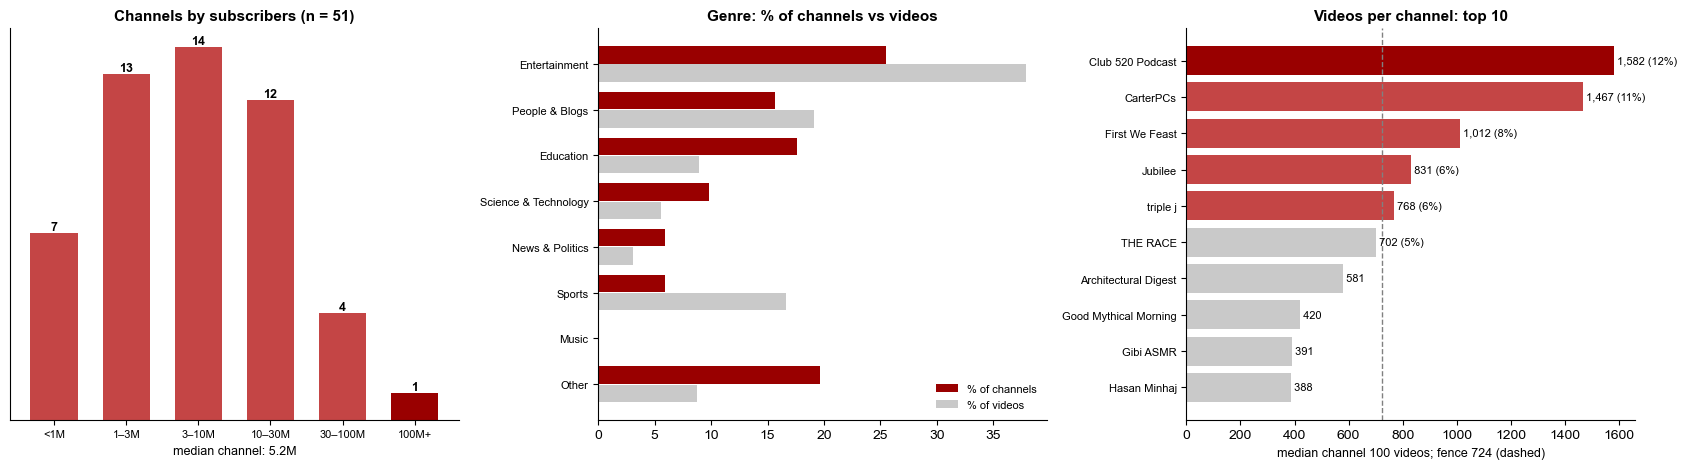

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
draw_subscribers(axes[0], df_channels)
draw_genre(axes[1], df_channels, df_videos)

draw_top_channels(axes[2], df_videos)
plt.tight_layout()
plt.show()

## All videos

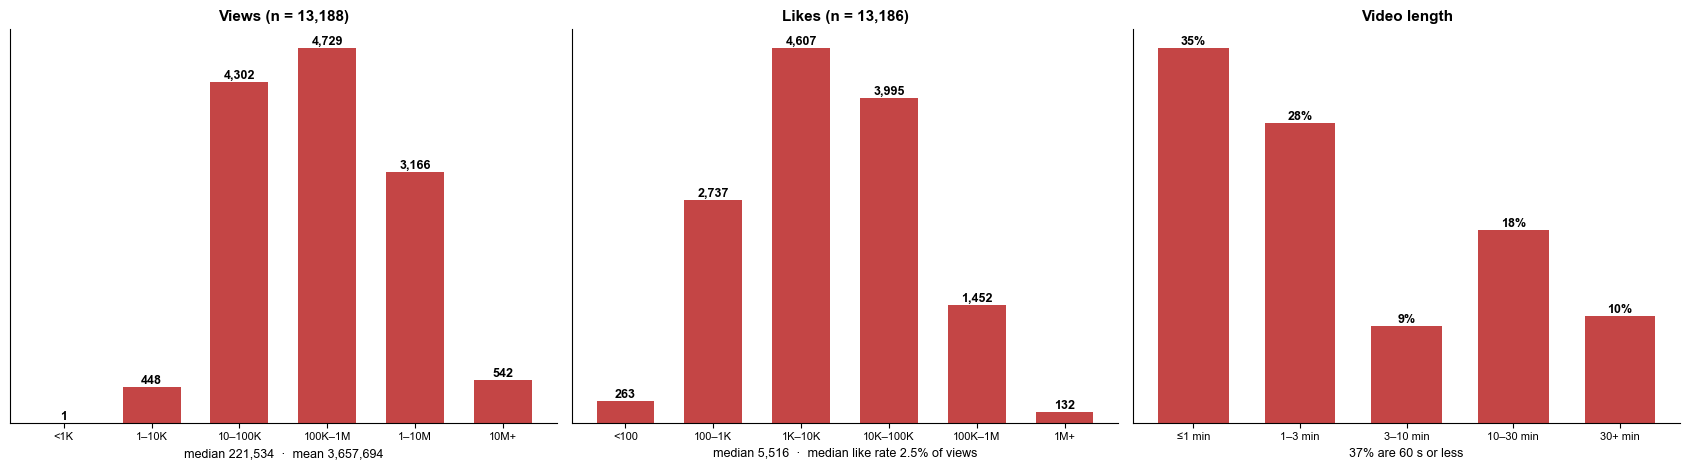

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
draw_views(axes[0], df_videos)
draw_likes(axes[1], df_videos)
draw_length(axes[2], df_videos)
plt.tight_layout()
plt.show()

## Training subset: channels

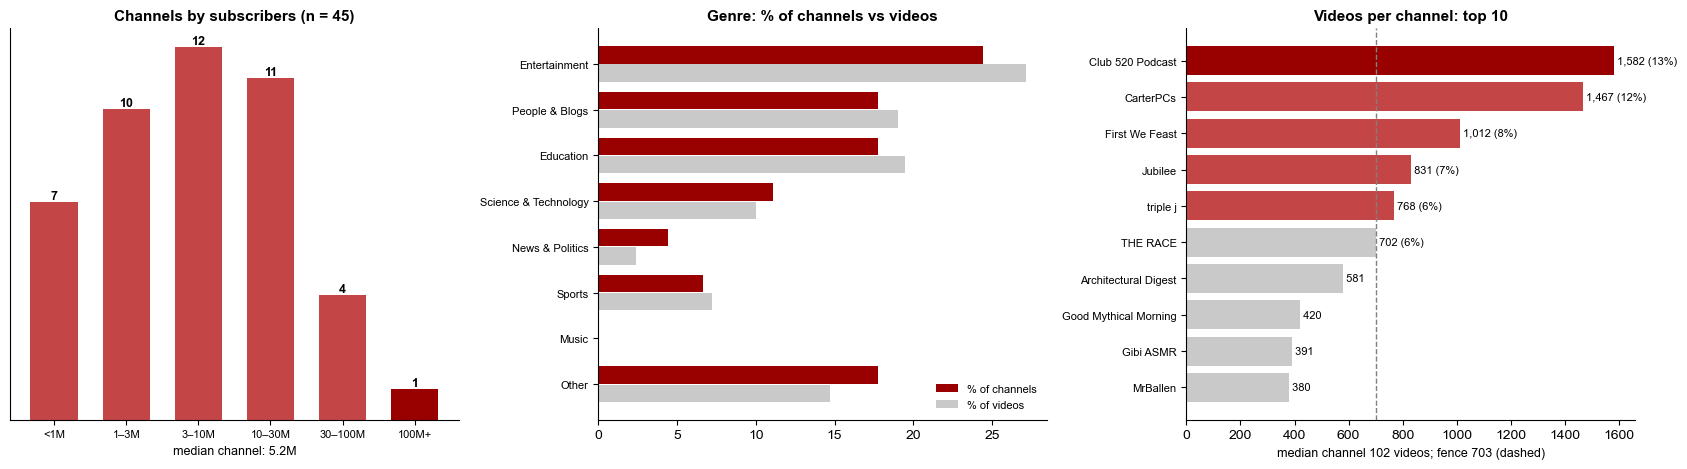

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
draw_subscribers(axes[0], df_channels_subset)
draw_genre(axes[1], df_channels_subset, df_subset)

# Same chart as All channels, counting each subset channel's uploads in the past year (CNBC is not in the subset).
draw_top_channels(axes[2], df_videos[df_videos["channel_id"].isin(df_subset["channel_id"])])
plt.tight_layout()
plt.show()

## Training subset: videos

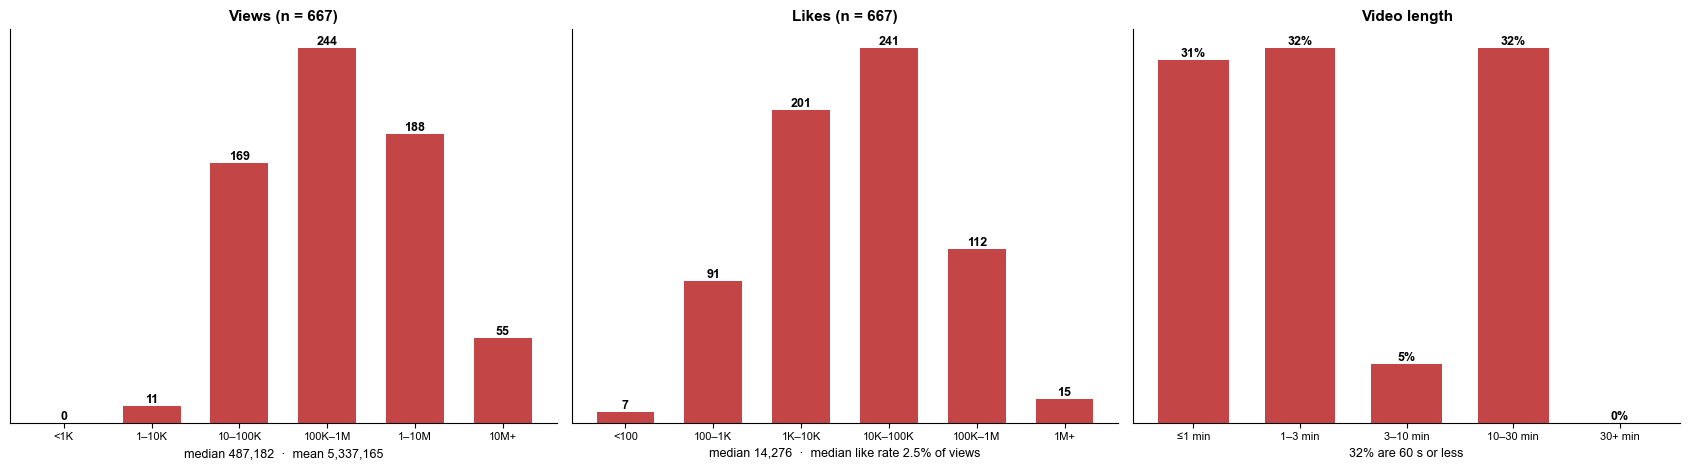

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
draw_views(axes[0], df_subset)
draw_likes(axes[1], df_subset)
draw_length(axes[2], df_subset)
plt.tight_layout()
plt.show()

## New channels

In [10]:
"""One row per channel: size, upload volume, format and typical performance over the past year. New = first
snapshot after the original 2026-10-15 list. Views are lifetime counts at the latest pull, so newer videos have
had less time to accumulate; median views per subscriber compares channels of different sizes."""
df_videos["is_short"] = df_videos["duration_seconds"] <= 60
df_videos["views_per_sub"] = df_videos["views"] / df_videos["channel_id"].map(df_channels.set_index("channel_id")["subs"])
df_profile = df_videos.groupby("channel_id").agg(
    videos_past_year=("id", "count"),
    shorts_share=("is_short", "mean"),
    median_views=("views", "median"),
    median_views_per_sub=("views_per_sub", "median"),
).reset_index()
df_profile = df_channels[["channel_id", "channel_title", "subs", "genre", "is_new"]].merge(df_profile, on="channel_id", how="left")
df_profile["videos_past_year"] = df_profile["videos_past_year"].fillna(0).astype(int)
df_profile.sort_values(["is_new", "subs"], ascending=[False, False]).round(3)

,channel_id,channel_title,subs,genre,is_new,videos_past_year,shorts_share,median_views,median_views_per_sub
50,UCBa659QWEk1AI4Tg--mrJ2A,Tom Scott,6740000,Education,True,31,0.000,1351979.0,0.201
47,UCazRf1jcMNZEL1MS5i_rWQQ,Midwest Safety,4880000,News & Politics,True,364,0.003,2276470.5,0.466
46,UCarEovlrD9QY-fy-Z6apIDQ,Hasan Minhaj,2220000,Comedy,True,388,0.206,79811.5,0.036
48,UCLVMKLtleeiKs0Oqp86ApTQ,Kelly Wakasa,2000000,Entertainment,True,50,0.620,178896.5,0.089
49,UCkk43V0FMRnQQSbG6s3VR3A,SauccEats,1580000,Howto & Style,True,54,0.741,3030230.5,1.918
0,UCX6OQ3DkcsbYNE6H8uQQuVA,MrBeast,522000000,Entertainment,False,98,0.704,141208793.0,0.271
30,UCY1kMZp36IQSyNx_9h4mpCg,Mark Rober,84300000,Science & Technology,False,42,0.571,17992244.5,0.213
33,UCRijo3ddMTht_IHyNSNXpNQ,Dude Perfect,62800000,Sports,False,143,0.776,4174132.0,0.066
3,UCMyOj6fhvKFMjxUCp3b_3gA,Nick DiGiovanni,47700000,People & Blogs,False,128,0.891,34372247.0,0.721
34,UCYzPXprvl5Y-Sf0g4vX-m6g,jacksepticeye,31100000,Gaming,False,79,0.000,2173104.0,0.07


In [11]:
"""Where each new channel falls among the existing channels (percentile 0-100 on each metric)."""
df_existing = df_profile[~df_profile["is_new"]]
metrics = ["subs", "videos_past_year", "shorts_share", "median_views", "median_views_per_sub"]
df_percentiles = df_profile[df_profile["is_new"]].set_index("channel_title")[metrics].apply(
    lambda column: column.apply(lambda value: (df_existing[column.name] < value).mean() * 100 if pd.notna(value) else np.nan))
df_percentiles.round(0)

,subs,videos_past_year,shorts_share,median_views,median_views_per_sub
channel_title,,,,,
Hasan Minhaj,33.0,80.0,50.0,24.0,22.0
Midwest Safety,46.0,78.0,20.0,76.0,83.0
Kelly Wakasa,28.0,24.0,85.0,35.0,37.0
SauccEats,22.0,24.0,91.0,80.0,100.0
Tom Scott,54.0,15.0,0.0,72.0,63.0


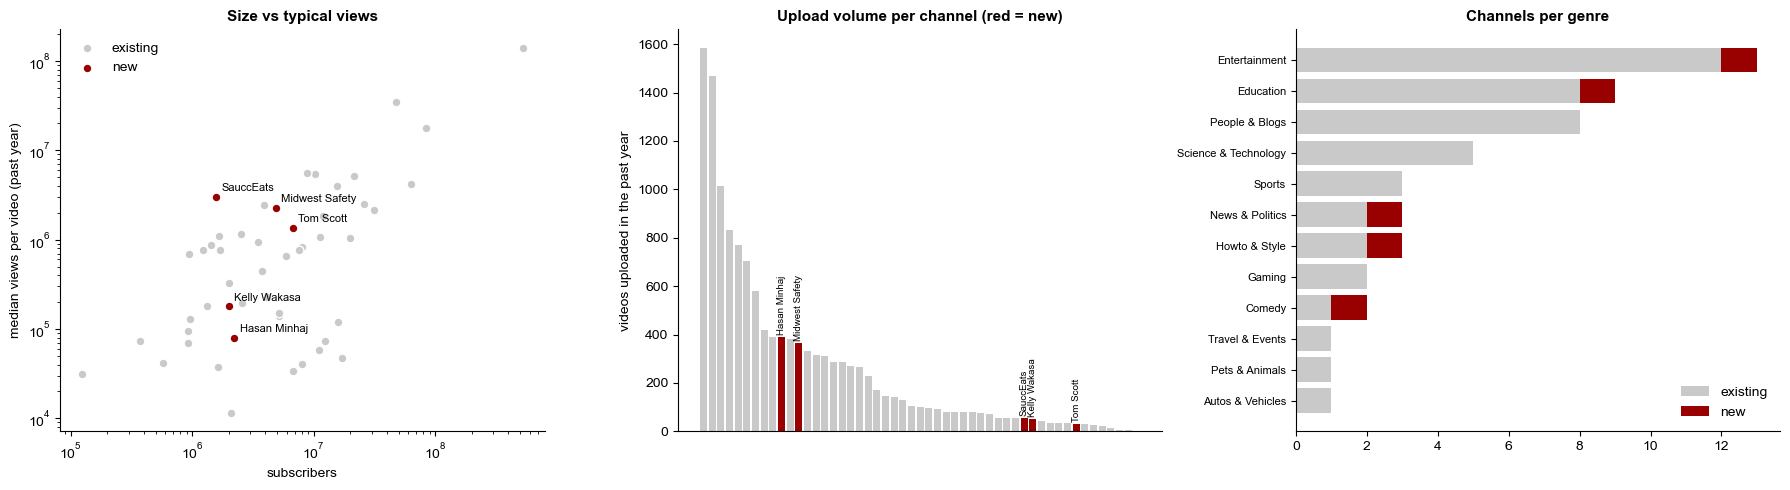

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for is_new, color, label in [(False, GRAY, "existing"), (True, RED, "new")]:
    df_group = df_profile[(df_profile["is_new"] == is_new) & (df_profile["videos_past_year"] > 0)]
    axes[0].scatter(df_group["subs"], df_group["median_views"], color=color, s=40, label=label, edgecolors="white")
for _, channel in df_profile[df_profile["is_new"] & (df_profile["videos_past_year"] > 0)].iterrows():
    axes[0].annotate(channel["channel_title"], (channel["subs"], channel["median_views"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("subscribers")
axes[0].set_ylabel("median views per video (past year)")
axes[0].legend(frameon=False)
axes[0].set_title("Size vs typical views", fontsize=11, fontweight="bold")

df_volume = df_profile.sort_values("videos_past_year", ascending=False)
axes[1].bar(range(len(df_volume)), df_volume["videos_past_year"], color=[RED if is_new else GRAY for is_new in df_volume["is_new"]])
for position, (_, channel) in enumerate(df_volume.iterrows()):
    if channel["is_new"]:
        axes[1].annotate(channel["channel_title"], (position, channel["videos_past_year"]), fontsize=7, rotation=90, xytext=(0, 3), textcoords="offset points", ha="center")
axes[1].set_xticks([])
axes[1].set_ylabel("videos uploaded in the past year")
axes[1].set_title("Upload volume per channel (red = new)", fontsize=11, fontweight="bold")

df_genre_counts = pd.crosstab(df_profile["genre"].fillna("no videos"), df_profile["is_new"]).reindex(columns=[False, True], fill_value=0)
df_genre_counts = df_genre_counts.loc[df_genre_counts.sum(axis=1).sort_values().index]
axes[2].barh(df_genre_counts.index, df_genre_counts[False], color=GRAY, label="existing")
axes[2].barh(df_genre_counts.index, df_genre_counts[True], left=df_genre_counts[False], color=RED, label="new")
axes[2].legend(frameon=False)
axes[2].set_title("Channels per genre", fontsize=11, fontweight="bold")
axes[2].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

## Numbers quoted on the slides

In [13]:
channel_counts = df_videos["channel_title"].value_counts()
print(f"{len(df_channels)} channels, {len(df_videos):,} videos; largest channel {channel_counts.index[0]} = {channel_counts.iloc[0] / len(df_videos):.0%} of videos, "
      f"top 3 = {channel_counts.head(3).sum() / len(df_videos):.0%}")
print(f"median views: all {df_videos['views'].median():,.0f} | subset {df_subset['views'].median():,.0f}")
print(f"subset: median age at latest pull {df_subset['age_days'].median():.0f} days (all videos: {df_videos['age_days'].median():.0f})")
hours_share = df_subset.loc[df_subset["duration_seconds"] > 600, "duration_seconds"].sum() / df_subset["duration_seconds"].sum()
print(f"subset: videos over 10 min are {hours_share:.0%} of the video hours")
print(f"Shorts (60 s or less): {(df_videos['duration_seconds'] <= 60).mean():.0%} of all videos, {(df_subset['duration_seconds'] <= 60).mean():.0%} of the subset")

51 channels, 13,188 videos; largest channel Club 520 Podcast = 12% of videos, top 3 = 31%
median views: all 221,534 | subset 487,182
subset: median age at latest pull 28 days (all videos: 183)
subset: videos over 10 min are 86% of the video hours
Shorts (60 s or less): 37% of all videos, 32% of the subset
